In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_squared_error, f1_score, mean_absolute_error, r2_score

# Models
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier, AdaBoostRegressor
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LinearRegression, LogisticRegression

In [2]:
df1 = pd.read_csv('Heart-Disease_dataset.csv')
df2 = pd.read_csv("Housing_dataset.csv")

In [3]:
# for classification
X = df1.drop("target", axis=1)
y = df1["target"]
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_clf)
X_test = scaler.transform(X_test_clf)

In [ ]:
#for regression
X = df2.drop("median_house_value", axis=1)
y = df2["median_house_value"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_reg)
X_test = scaler.transform(X_test_reg)

In [15]:
#GridSearch on All Classification Models
param_grids = {
    "DecisionTree": (DecisionTreeClassifier(), {
        "max_depth": [3, 5, 10],
        "min_samples_split": [2, 5, 10]
    }),
    "NaiveBayes": (GaussianNB(), {
        "var_smoothing": [1e-9, 1e-8, 1e-7]
    }),
    "MLP": (MLPClassifier(max_iter=2000, early_stopping=True), {
        "hidden_layer_sizes": [(50,), (100,), (50, 50)],
        "activation": ["relu", "tanh"],
        "learning_rate_init": [0.001, 0.01]
    }),
    "KNN": (KNeighborsClassifier(), {
        "n_neighbors": [3, 5, 7, 9],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    }),
    "RandomForest": (RandomForestClassifier(), {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10]
    }),
    "SVC": (SVC(), {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    }),
    "AdaBoost": (AdaBoostClassifier(), {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.5, 1, 1.5]
    }),
    "LogisticRegression": (LogisticRegression(max_iter=2000), {
        "C": [0.1, 1, 10],
        "solver": ["lbfgs", "liblinear"]
    })
}

clf_results = []
for name, (model, param_grid) in param_grids.items():
    grid = GridSearchCV(model, param_grid, cv=5, scoring="accuracy")
    grid.fit(X_train_clf, y_train_clf)
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test_clf)
    acc = accuracy_score(y_test_clf, y_pred)
    f1 = f1_score(y_test_clf, y_pred)
    clf_results.append([name, acc, f1, grid.best_params_])

df_clf_results = pd.DataFrame(clf_results, columns=["Model", "Accuracy", "F1", "Best Params"])
print(df_clf_results)
print("\nBest Classification Model:")
print(df_clf_results.sort_values(by="Accuracy", ascending=False).iloc[0])

                Model  Accuracy        F1  \
0        DecisionTree  0.819672  0.825397   
1          NaiveBayes  0.868852  0.870968   
2                 MLP  0.737705  0.764706   
3                 KNN  0.704918  0.709677   
4        RandomForest  0.836066  0.843750   
5                 SVC  0.868852  0.875000   
6            AdaBoost  0.819672  0.813559   
7  LogisticRegression  0.868852  0.875000   

                                         Best Params  
0           {'max_depth': 3, 'min_samples_split': 5}  
1                           {'var_smoothing': 1e-09}  
2  {'activation': 'tanh', 'hidden_layer_sizes': (...  
3  {'metric': 'manhattan', 'n_neighbors': 7, 'wei...  
4             {'max_depth': 10, 'n_estimators': 200}  
5                       {'C': 1, 'kernel': 'linear'}  
6           {'learning_rate': 1, 'n_estimators': 50}  
7                    {'C': 1, 'solver': 'liblinear'}  

Best Classification Model:
Model                        NaiveBayes
Accuracy                       

In [14]:
# Cell 10 - GridSearch on All Regression Models
param_grids = {
    "DecisionTree": (DecisionTreeRegressor(), {
        "max_depth": [3, 5, 10],
        "min_samples_split": [2, 5, 10]
    }),
    "MLP": (MLPRegressor(max_iter=2000, early_stopping=True), {
        "hidden_layer_sizes": [(50,), (100,), (50, 50)],
        "activation": ["relu", "tanh"],
        "learning_rate_init": [0.001, 0.01]
    }),
    "KNN": (KNeighborsRegressor(), {
        "n_neighbors": [3, 5, 7, 9],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    }),
    "RandomForest": (RandomForestRegressor(), {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10]
    }),
    "SVM": (SVR(), {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    }),
    "AdaBoost": (AdaBoostRegressor(), {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.5, 1, 1.5]
    }),
    "LinearRegression": (LinearRegression(), {})
}

reg_results = []
for name, (model, param_grid) in param_grids.items():
    if param_grid:
        grid = GridSearchCV(model, param_grid, cv=5, scoring="r2")
        grid.fit(X_train_reg, y_train_reg)
        best_model = grid.best_estimator_
        best_params = grid.best_params_
    else:
        best_model = model
        best_model.fit(X_train_reg, y_train_reg)
        best_params = {}

    y_pred = best_model.predict(X_test_reg)
    mae = mean_absolute_error(y_test_reg, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred))
    r2 = r2_score(y_test_reg, y_pred)
    reg_results.append([name, mae, rmse, r2, best_params])

df_reg_results = pd.DataFrame(reg_results, columns=["Model", "MAE", "RMSE", "R2", "Best Params"])
print(df_reg_results)
print("\nBest Regression Model (by R2):")
print(df_reg_results.sort_values(by="R2", ascending=False).iloc[0])

NameError: name 'X_train_reg' is not defined

In [16]:
y_prediction = best_model.predict(X_test_clf)
print("MAE:", mean_absolute_error(y_test_clf, y_prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_test_clf, y_prediction)))
print("R2:", r2_score(y_test_clf, y_prediction))

MAE: 0.13114754098360656
RMSE: 0.3621429841700741
R2: 0.47413793103448276


In [ ]:
y_prediction = best_model.predict(X_test_reg)
print("MAE:", mean_absolute_error(y_test_reg, y_prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, y_prediction)))
print("R2:", r2_score(y_test_reg, y_prediction))

Best Model: NaiveBayes


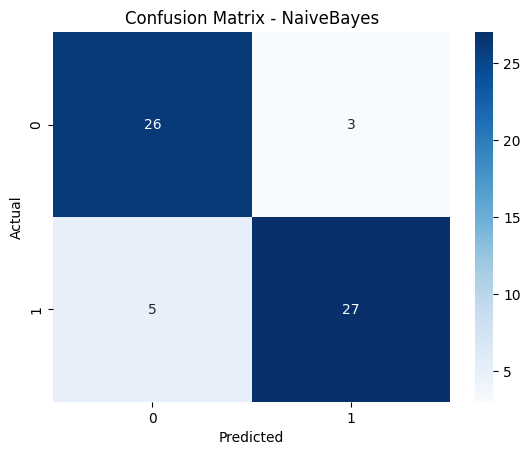

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_clf_name = df_clf_results.sort_values(by="Accuracy", ascending=False).iloc[0]["Model"]
print(f"Best Model: {best_clf_name}")

for name, (model, param_grid) in param_grids.items():
    if name == best_clf_name:
        grid = GridSearchCV(model, param_grid, cv=5, scoring="accuracy")
        grid.fit(X_train_clf, y_train_clf)
        best_clf = grid.best_estimator_
        y_pred = best_clf.predict(X_test_clf)
        
        cm = confusion_matrix(y_test_clf, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
        plt.title(f"Confusion Matrix - {name}")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

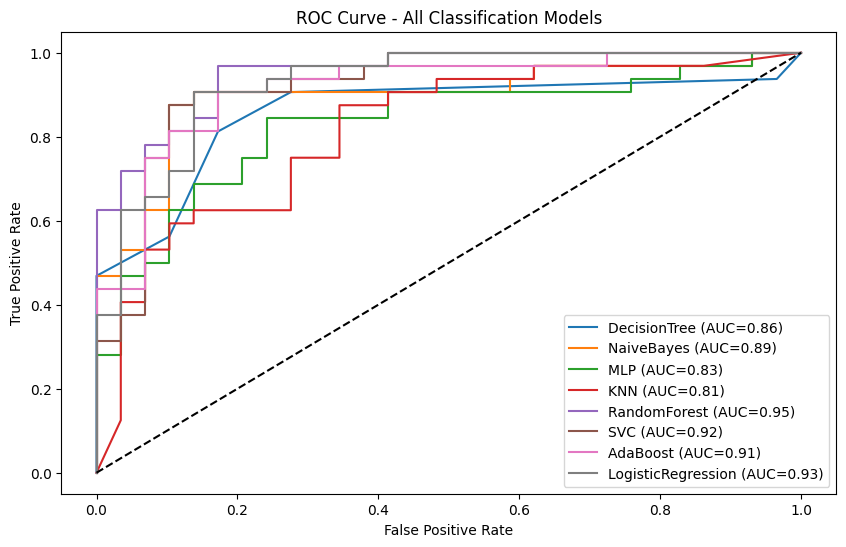

In [19]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 6))
for name, (model, param_grid) in param_grids.items():
    grid = GridSearchCV(model, param_grid, cv=5, scoring="accuracy")
    grid.fit(X_train_clf, y_train_clf)
    best_model = grid.best_estimator_
    
    if hasattr(best_model, "predict_proba"):
        y_prob = best_model.predict_proba(X_test_clf)[:, 1]
    else:
        y_prob = best_model.decision_function(X_test_clf)
    
    fpr, tpr, _ = roc_curve(y_test_clf, y_prob)
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - All Classification Models")
plt.legend()
plt.show()

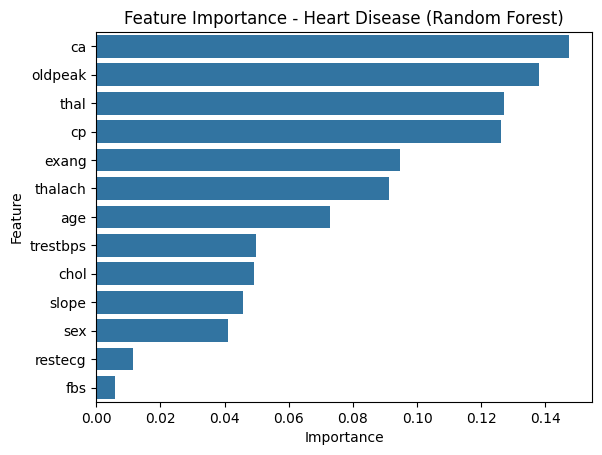

In [20]:
import pandas as pd

feature_names = df1.drop("target", axis=1).columns

rf_clf = RandomForestClassifier(**{'max_depth': 5, 'n_estimators': 100})
rf_clf.fit(X_train_clf, y_train_clf)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_clf.feature_importances_
}).sort_values(by="Importance", ascending=False)

sns.barplot(x="Importance", y="Feature", data=importance_df)
plt.title("Feature Importance - Heart Disease (Random Forest)")
plt.show()

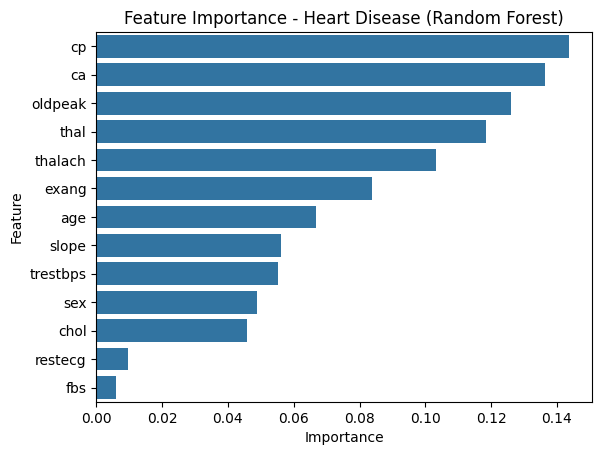

In [21]:
import pandas as pd

feature_names = df1.drop("target", axis=1).columns

rf_clf = RandomForestClassifier(**{'max_depth': 5, 'n_estimators': 100})
rf_clf.fit(X_train_clf, y_train_clf)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_clf.feature_importances_
}).sort_values(by="Importance", ascending=False)

sns.barplot(x="Importance", y="Feature", data=importance_df)
plt.title("Feature Importance - Heart Disease (Random Forest)")
plt.show()

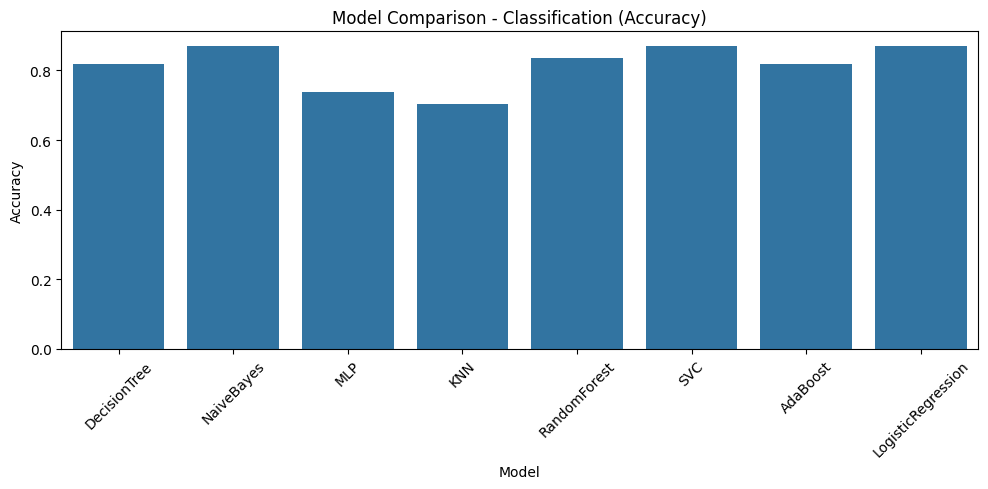

NameError: name 'df_reg_results' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
# Classification
plt.figure(figsize=(10, 5))
sns.barplot(x="Model", y="Accuracy", data=df_clf_results)
plt.title("Model Comparison - Classification (Accuracy)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Regression
plt.figure(figsize=(10, 5))
sns.barplot(x="Model", y="R2", data=df_reg_results)
plt.title("Model Comparison - Regression (R2)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

=== Best Classification Model ===
Model: NaiveBayes
Accuracy: 0.8689
F1: 0.8710
Best Params: {'var_smoothing': 1e-09}
دلیل انتخاب: بالاترین Accuracy و F1 را در بین تمام مدل‌ها دارد


NameError: name 'df_reg_results' is not defined

In [24]:
# Classification
best_clf = df_clf_results.sort_values(by="Accuracy", ascending=False).iloc[0]
print("=== Best Classification Model ===")
print(f"Model: {best_clf['Model']}")
print(f"Accuracy: {best_clf['Accuracy']:.4f}")
print(f"F1: {best_clf['F1']:.4f}")
print(f"Best Params: {best_clf['Best Params']}")
print("دلیل انتخاب: بالاترین Accuracy و F1 را در بین تمام مدل‌ها دارد")


=== Best Classification Model ===
Model: NaiveBayes
Accuracy: 0.8689
F1: 0.8710
Best Params: {'var_smoothing': 1e-09}
دلیل انتخاب: بالاترین Accuracy و F1 را در بین تمام مدل‌ها دارد


In [ ]:
# Regression
best_reg = df_reg_results.sort_values(by="R2", ascending=False).iloc[0]
print("\n=== Best Regression Model ===")
print(f"Model: {best_reg['Model']}")
print(f"MAE: {best_reg['MAE']:.4f}")
print(f"RMSE: {best_reg['RMSE']:.4f}")
print(f"R2: {best_reg['R2']:.4f}")
print(f"Best Params: {best_reg['Best Params']}")
print("دلیل انتخاب: بالاترین R2 و پایین‌ترین MAE و RMSE را دارد")